### Эксперименты:
`
Модель для экспериментов: ResNet18
Датасет для экспериментов: CIFAR10
Оптимизаторы для сравнения: SGD, Momentum, AdaGrad, AdamW, Lion

Первый эксперимент: сравнение разных оптимизаторов при обучении ResNet18 на датасете и результаты в виде графиков TrainLoss, ValLoss, TrainAccuracy, ValAccuracy

Второй эксперимент: сравнение AdamW и Lion с разными батчсайзами для даталоадера, в результате графики сравнения при разных батчсайзах и также затрачиваемая память для state оптимизатора
`

In [1]:
import os
import time
import copy

import torch
import pandas as pd
import matplotlib.pyplot as plt

from torch import nn
from torch.optim import SGD, Adagrad, AdamW
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
from torchvision.models import resnet18

d:\Projects\ITMO\EfficientNN\venv\Lib\site-packages\torch\cuda\__init__.py:68: FutureWarning: The pynvml package is deprecated. Please install nvidia-ml-py instead. If you did not install pynvml directly, please report this to the maintainers of the package that installed pynvml for you.
  import pynvml  # type: ignore[import]


In [2]:
def get_cifar10_loaders(batch_size=128, num_workers=4):
    train_transform = transforms.Compose([
        transforms.RandomCrop(32, padding=4),
        transforms.RandomHorizontalFlip(),
        transforms.ToTensor(),
        transforms.Normalize(
            (0.4914, 0.4822, 0.4465),
            (0.2470, 0.2435, 0.2616),
        ),
    ])

    test_transform = transforms.Compose([
        transforms.ToTensor(),
        transforms.Normalize(
            (0.4914, 0.4822, 0.4465),
            (0.2470, 0.2435, 0.2616),
        ),
    ])

    train_dataset = datasets.CIFAR10(
        root="./data",
        train=True,
        download=False,
        transform=train_transform,
    )

    test_dataset = datasets.CIFAR10(
        root="./data",
        train=False,
        download=False,
        transform=test_transform,
    )

    train_loader = DataLoader(
        train_dataset,
        batch_size=batch_size,
        shuffle=True,
        num_workers=num_workers,
        pin_memory=True,
    )

    test_loader = DataLoader(
        test_dataset,
        batch_size=batch_size,
        shuffle=False,
        num_workers=num_workers,
        pin_memory=True,
    )

    return train_loader, test_loader

In [3]:
def get_resnet18():
    model = resnet18(weights=None)

    model.conv1 = nn.Conv2d(
        3,
        64,
        kernel_size=3,
        stride=1,
        padding=1,
        bias=False,
    )

    model.maxpool = nn.Identity()
    model.fc = nn.Linear(model.fc.in_features, 10)

    return model

In [4]:
def train_model(
    model,
    optimizer,
    train_loader,
    test_loader,
    epochs,
    device,
):
    criterion = nn.CrossEntropyLoss()

    history = []

    for epoch in range(epochs):
        model.train()

        train_loss = 0.0
        train_correct = 0
        train_total = 0

        start_time = time.perf_counter()

        for images, labels in train_loader:
            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)

            optimizer.zero_grad()

            outputs = model(images)

            loss = criterion(outputs, labels)

            loss.backward()
            optimizer.step()

            train_loss += loss.item() * images.size(0)

            predictions = outputs.argmax(dim=1)

            train_correct += (
                predictions == labels
            ).sum().item()

            train_total += labels.size(0)

        if device.startswith("cuda"):
            torch.cuda.synchronize()

        epoch_time = time.perf_counter() - start_time

        train_loss /= train_total
        train_accuracy = train_correct / train_total

        model.eval()

        val_loss = 0.0
        val_correct = 0
        val_total = 0

        with torch.inference_mode():
            for images, labels in test_loader:
                images = images.to(device, non_blocking=True)
                labels = labels.to(device, non_blocking=True)

                outputs = model(images)

                loss = criterion(outputs, labels)

                val_loss += loss.item() * images.size(0)

                predictions = outputs.argmax(dim=1)

                val_correct += (
                    predictions == labels
                ).sum().item()

                val_total += labels.size(0)

        val_loss /= val_total
        val_accuracy = val_correct / val_total

        history.append({
            "epoch": epoch + 1,
            "train_loss": train_loss,
            "val_loss": val_loss,
            "train_accuracy": train_accuracy,
            "val_accuracy": val_accuracy,
            "epoch_time": epoch_time,
        })

        print(
            f"Epoch {epoch + 1:02d}/{epochs} | "
            f"train loss: {train_loss:.4f} | "
            f"val loss: {val_loss:.4f} | "
            f"train acc: {train_accuracy:.4f} | "
            f"val acc: {val_accuracy:.4f}"
        )

    return pd.DataFrame(history)

In [5]:
def optimizer_state_bytes(optimizer):
    total = 0

    for state in optimizer.state.values():
        for value in state.values():
            if torch.is_tensor(value):
                total += (
                    value.numel()
                    * value.element_size()
                )

    return total

In [6]:
from Lion import Lion


def experiment_optimizers(
    epochs=30,
    batch_size=128,
    device="cuda",
    output_dir="results/experiment_1",
):
    os.makedirs(output_dir, exist_ok=True)

    train_loader, test_loader = get_cifar10_loaders(
        batch_size=batch_size
    )

    optimizer_configs = {
        "SGD": {
            "class": SGD,
            "kwargs": {
                "lr": 0.1,
            },
        },

        "Momentum": {
            "class": SGD,
            "kwargs": {
                "lr": 0.1,
                "momentum": 0.9,
            },
        },

        "AdaGrad": {
            "class": Adagrad,
            "kwargs": {
                "lr": 0.01,
            },
        },

        "AdamW": {
            "class": AdamW,
            "kwargs": {
                "lr": 1e-3,
                "weight_decay": 1e-2,
            },
        },

        "Lion": {
            "class": Lion,
            "kwargs": {
                "lr": 1e-4,
                "betas": (0.9, 0.99),
                "weight_decay": 1e-1,
            },
        },
    }

    all_history = []

    summary = []

    for optimizer_name, config in optimizer_configs.items():
        print()
        print("=" * 60)
        print(f"Optimizer: {optimizer_name}")
        print("=" * 60)

        torch.manual_seed(42)

        model = get_resnet18().to(device)

        optimizer = config["class"](
            model.parameters(),
            **config["kwargs"],
        )

        history = train_model(
            model=model,
            optimizer=optimizer,
            train_loader=train_loader,
            test_loader=test_loader,
            epochs=epochs,
            device=device,
        )

        history["optimizer"] = optimizer_name
        history["batch_size"] = batch_size

        all_history.append(history)

        state_bytes = optimizer_state_bytes(
            optimizer
        )

        summary.append({
            "optimizer": optimizer_name,
            "batch_size": batch_size,

            "best_val_accuracy":
                history["val_accuracy"].max(),

            "final_val_accuracy":
                history["val_accuracy"].iloc[-1],

            "final_val_loss":
                history["val_loss"].iloc[-1],

            "mean_epoch_time":
                history["epoch_time"].mean(),

            "optimizer_state_mb":
                state_bytes / 1024**2,
        })

        del model
        del optimizer

        if device.startswith("cuda"):
            torch.cuda.empty_cache()

    history_df = pd.concat(
        all_history,
        ignore_index=True,
    )

    summary_df = pd.DataFrame(summary)

    history_df.to_csv(
        os.path.join(
            output_dir,
            "optimizer_history.csv",
        ),
        index=False,
    )

    summary_df.to_csv(
        os.path.join(
            output_dir,
            "optimizer_summary.csv",
        ),
        index=False,
    )

    fig, axes = plt.subplots(
        2,
        2,
        figsize=(14, 10),
    )

    for optimizer_name in optimizer_configs:
        part = history_df[
            history_df["optimizer"]
            == optimizer_name
        ]

        axes[0, 0].plot(
            part["epoch"],
            part["train_loss"],
            label=optimizer_name,
        )

        axes[0, 1].plot(
            part["epoch"],
            part["val_loss"],
            label=optimizer_name,
        )

        axes[1, 0].plot(
            part["epoch"],
            part["train_accuracy"],
            label=optimizer_name,
        )

        axes[1, 1].plot(
            part["epoch"],
            part["val_accuracy"],
            label=optimizer_name,
        )

    axes[0, 0].set_title("Train loss")
    axes[0, 1].set_title("Validation loss")
    axes[1, 0].set_title("Train accuracy")
    axes[1, 1].set_title("Validation accuracy")

    for ax in axes.flat:
        ax.set_xlabel("Epoch")
        ax.grid(True)
        ax.legend()

    plt.tight_layout()

    plt.savefig(
        os.path.join(
            output_dir,
            "optimizer_comparison.png",
        ),
        dpi=200,
    )

    plt.show()

    return history_df, summary_df


Optimizer: SGD
Epoch 01/30 | train loss: 1.7364 | val loss: 1.6801 | train acc: 0.3646 | val acc: 0.4151
Epoch 02/30 | train loss: 1.2253 | val loss: 1.2172 | train acc: 0.5522 | val acc: 0.5820
Epoch 03/30 | train loss: 0.9679 | val loss: 0.9184 | train acc: 0.6538 | val acc: 0.6793
Epoch 04/30 | train loss: 0.8113 | val loss: 1.2003 | train acc: 0.7135 | val acc: 0.6298
Epoch 05/30 | train loss: 0.7036 | val loss: 0.9344 | train acc: 0.7536 | val acc: 0.6960
Epoch 06/30 | train loss: 0.6260 | val loss: 0.6606 | train acc: 0.7796 | val acc: 0.7793
Epoch 07/30 | train loss: 0.5584 | val loss: 0.6339 | train acc: 0.8065 | val acc: 0.7834
Epoch 08/30 | train loss: 0.5136 | val loss: 0.8420 | train acc: 0.8224 | val acc: 0.7414
Epoch 09/30 | train loss: 0.4723 | val loss: 0.6994 | train acc: 0.8352 | val acc: 0.7737
Epoch 10/30 | train loss: 0.4376 | val loss: 0.6094 | train acc: 0.8487 | val acc: 0.7997
Epoch 11/30 | train loss: 0.4060 | val loss: 0.5471 | train acc: 0.8585 | val acc: 0

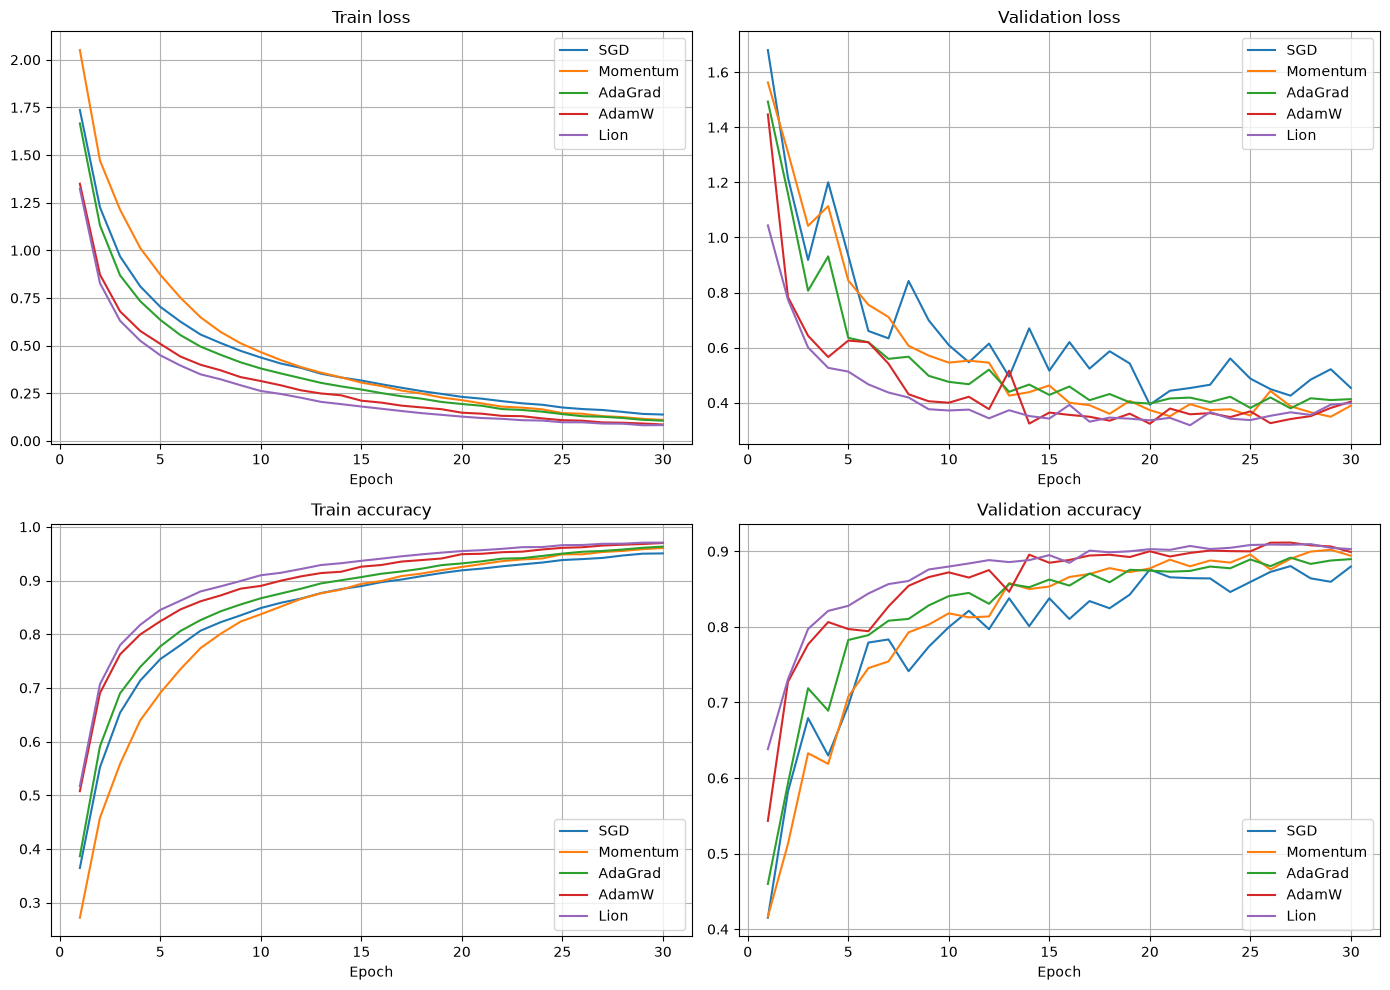

In [7]:
history_1, summary_1 = experiment_optimizers(
    epochs=30,
    batch_size=128,
)

In [8]:
batch_sizes = [32, 128, 512, 1024]

In [9]:
def experiment_batch_sizes(
    batch_sizes=(32, 128, 512),
    epochs=30,
    device="cuda",
    output_dir="results/experiment_2",
):
    os.makedirs(output_dir, exist_ok=True)

    optimizer_configs = {
        "AdamW": {
            "class": AdamW,
            "kwargs": {
                "lr": 1e-3,
                "weight_decay": 1e-2,
            },
        },

        "Lion": {
            "class": Lion,
            "kwargs": {
                "lr": 1e-4,
                "betas": (0.9, 0.99),
                "weight_decay": 1e-1,
            },
        },
    }

    all_history = []
    summary = []

    for batch_size in batch_sizes:
        train_loader, test_loader = get_cifar10_loaders(
            batch_size=batch_size
        )

        for optimizer_name, config in optimizer_configs.items():
            print()
            print("=" * 60)
            print(
                f"{optimizer_name} | "
                f"batch_size={batch_size}"
            )
            print("=" * 60)

            torch.manual_seed(42)

            model = get_resnet18().to(device)

            optimizer = config["class"](
                model.parameters(),
                **config["kwargs"],
            )

            history = train_model(
                model=model,
                optimizer=optimizer,
                train_loader=train_loader,
                test_loader=test_loader,
                epochs=epochs,
                device=device,
            )

            history["optimizer"] = optimizer_name
            history["batch_size"] = batch_size

            all_history.append(history)

            state_bytes = optimizer_state_bytes(
                optimizer
            )

            summary.append({
                "optimizer": optimizer_name,
                "batch_size": batch_size,

                "best_val_accuracy":
                    history["val_accuracy"].max(),

                "final_val_accuracy":
                    history["val_accuracy"].iloc[-1],

                "final_val_loss":
                    history["val_loss"].iloc[-1],

                "mean_epoch_time":
                    history["epoch_time"].mean(),

                "optimizer_state_bytes":
                    state_bytes,

                "optimizer_state_mb":
                    state_bytes / 1024**2,
            })

            del model
            del optimizer

            if device.startswith("cuda"):
                torch.cuda.empty_cache()

    history_df = pd.concat(
        all_history,
        ignore_index=True,
    )

    summary_df = pd.DataFrame(summary)

    history_df.to_csv(
        os.path.join(
            output_dir,
            "batch_history.csv",
        ),
        index=False,
    )

    summary_df.to_csv(
        os.path.join(
            output_dir,
            "batch_summary.csv",
        ),
        index=False,
    )

    fig, axes = plt.subplots(
        1,
        2,
        figsize=(14, 5),
    )

    for optimizer_name in ["AdamW", "Lion"]:
        part = summary_df[
            summary_df["optimizer"]
            == optimizer_name
        ]

        axes[0].plot(
            part["batch_size"],
            part["best_val_accuracy"],
            marker="o",
            label=optimizer_name,
        )

        axes[1].plot(
            part["batch_size"],
            part["mean_epoch_time"],
            marker="o",
            label=optimizer_name,
        )

    axes[0].set_title(
        "Best validation accuracy vs batch size"
    )
    axes[0].set_xlabel("Batch size")
    axes[0].set_ylabel("Accuracy")
    axes[0].grid(True)
    axes[0].legend()

    axes[1].set_title(
        "Mean epoch time vs batch size"
    )
    axes[1].set_xlabel("Batch size")
    axes[1].set_ylabel("Seconds")
    axes[1].grid(True)
    axes[1].legend()

    plt.tight_layout()

    plt.savefig(
        os.path.join(
            output_dir,
            "batch_comparison.png",
        ),
        dpi=200,
    )

    plt.show()

    # отдельный график optimizer state
    pivot = summary_df.pivot(
        index="batch_size",
        columns="optimizer",
        values="optimizer_state_mb",
    )

    pivot.plot(
        kind="bar",
        figsize=(8, 5),
    )

    plt.ylabel("Optimizer state, MB")
    plt.title("Optimizer state memory")
    plt.grid(axis="y")
    plt.tight_layout()

    plt.savefig(
        os.path.join(
            output_dir,
            "optimizer_state_memory.png",
        ),
        dpi=200,
    )

    plt.show()

    return history_df, summary_df

In [ ]:
history_2, summary_2 = experiment_batch_sizes(
    batch_sizes=batch_sizes,
    epochs=30,
)


AdamW | batch_size=32
Epoch 01/30 | train loss: 1.3960 | val loss: 1.0020 | train acc: 0.4932 | val acc: 0.6453
Epoch 02/30 | train loss: 0.9053 | val loss: 0.8038 | train acc: 0.6797 | val acc: 0.7189
Epoch 03/30 | train loss: 0.7087 | val loss: 0.6405 | train acc: 0.7536 | val acc: 0.7852
Epoch 04/30 | train loss: 0.5926 | val loss: 0.5444 | train acc: 0.7959 | val acc: 0.8158
Epoch 05/30 | train loss: 0.5182 | val loss: 0.5500 | train acc: 0.8240 | val acc: 0.8174
Epoch 06/30 | train loss: 0.4563 | val loss: 0.4733 | train acc: 0.8419 | val acc: 0.8410
Epoch 07/30 | train loss: 0.4105 | val loss: 0.4315 | train acc: 0.8593 | val acc: 0.8558
Epoch 08/30 | train loss: 0.3770 | val loss: 0.3753 | train acc: 0.8712 | val acc: 0.8699
Epoch 09/30 | train loss: 0.3344 | val loss: 0.3855 | train acc: 0.8842 | val acc: 0.8694
Epoch 10/30 | train loss: 0.3104 | val loss: 0.4094 | train acc: 0.8927 | val acc: 0.8581
Epoch 11/30 | train loss: 0.2877 | val loss: 0.3392 | train acc: 0.9009 | val